---

# Data Pipeline

---

In [ ]:
# Load in the relevant libraries
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import re

In [21]:
# Define the condition
CONDITION = "aig" 

# Define the paths where the json files are located.
JSON_DIR = Path(f"pmc/{CONDITION}/json")

# Define the path of the processed files.
OUTPUT_DIR = Path(f"pmc/{CONDITION}/processed")

# If the path does not exist, then create it.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [22]:
# We can check whether the JSON files exist
json_files = list(JSON_DIR.glob("*.jats.json"))

print("JSON folder:", JSON_DIR.resolve())
print("JSON files found:", len(json_files))


JSON folder: C:\Users\caral\OneDrive\Documents\SCI501\SCI501_Project\pmc\aig\json
JSON files found: 152


In [23]:
# We will create two empty lists to store article details and text passages
articles = []
passages = []

# Go through each downloaded JSON file in the folder
# We will sort the files so they can be processed in order
for file in sorted(json_files):

    # We will open the JSON file using UTF-8 to read special characters
    with open(file, encoding="utf-8") as f:
        data = json.load(f)

    # Get the article metadata and passages from the JATS JSON file
    metadata = data.get("metadata") or {}
    content = data.get("passages") or []

    # Get the PMC ID from the JSON file
    # Remove the .jats.json extension
    pmcid = data.get("pmcid", file.name.replace(".jats.json", ""))

    # Get the publication year from the article citation
    # The year is not stored as a separate field in PMC Cloud metadata
    citation = metadata.get("citation") or ""

    # Find a four-digit publication year in the citation
    year_match = re.search(r"\b(?:19|20)\d{2}\b", citation)

    # Convert the year to a number
    # If the year is missing or invalid, we can store it as NaN
    year = (
        int(year_match.group())
        if year_match else float("nan")
    )

    # We will store one record for each article
    # We keep the main metadata (can be used for later analysis)
    articles.append({
        "pmcid": pmcid,
        "title": metadata.get("title", ""),
        "year": year,
        "doi": metadata.get("doi"),
        "pmid": metadata.get("pmid"),
        "license": metadata.get("license_code")
    })

    # Loop through each passage in the article
    # We will give each passage a number so it can be identified later
    for i, passage in enumerate(content):

        # We extract the text and remove extra spaces at the beginning
        # and end
        text = (passage.get("text") or "").strip()

        # Skip passages that don't contain any text
        if not text:
            continue

        # Get the section information for the current passage
        # JATS stores sections as a list of nested headings
        section_path = passage.get("section") or []

        # Store each passage as a separate record
        # We will keep the PMC ID so the text can be linked to original
        # record
        passages.append({
            "pmcid": pmcid,
            "passage_id": passage.get("passage_id", i),
            "year": year,
            "section": " > ".join(section_path),
            "type": passage.get("type", ""),
            "text": text,
            "word_count": len(text.split())
        })

# Check how many articles and passages were extracted
print("Articles processed:", len(articles))
print("Passages extracted:", len(passages))


Articles processed: 152
Passages extracted: 4131


In [24]:
print(data["metadata"].keys())
print(data["metadata"])

dict_keys(['pmcid', 'version', 'pmid', 'doi', 'mid', 'title', 'citation', 'is_pmc_openaccess', 'is_manuscript', 'is_historical_ocr', 'is_retracted', 'license_code', 'xml_url', 'text_url', 'pdf_url', 'media_urls'])
{'pmcid': 'PMC9966253', 'version': 1, 'pmid': 36834698, 'doi': '10.3390/ijms24043290', 'mid': None, 'title': 'A DSC Test for the Early Detection of Neoplastic Gastric Lesions in a Medium-Risk Gastric Cancer Area', 'citation': 'Int J Mol Sci. 2023 Feb 7;24(4):3290. doi: 10.3390/ijms24043290', 'is_pmc_openaccess': True, 'is_manuscript': False, 'is_historical_ocr': False, 'is_retracted': False, 'license_code': 'CC BY', 'xml_url': 's3://pmc-oa-opendata/PMC9966253.1/PMC9966253.1.xml?md5=ff806109c42e94141a8fdf947705585f', 'text_url': 's3://pmc-oa-opendata/PMC9966253.1/PMC9966253.1.txt?md5=7b0b5341c279e2773aaf764197178a22', 'pdf_url': 's3://pmc-oa-opendata/PMC9966253.1/PMC9966253.1.pdf?md5=4c9794e1e53961dbcec4f75c2ff1b8c0', 'media_urls': ['s3://pmc-oa-opendata/PMC9966253.1/ijms-24-0

In [25]:
# Convert the article and passage lists into pandas DataFrames
# so data is easier to organise and analyse
articles_df = pd.DataFrame(articles)
passages_df = pd.DataFrame(passages)

# Check whether any articles or passages were extracted
# Stop the code if either DataFrame is empty
if articles_df.empty or passages_df.empty:
    raise ValueError("No usable JATS articles found.")

# Remove duplicate articles based on their PMC ID
# This ensures each article only appears once in the article dataset
articles_df = articles_df.drop_duplicates(
    subset="pmcid"
)

In [26]:
# Save the article metadata in Parquet format
# Each row contains information about one article
articles_df.to_parquet(
    OUTPUT_DIR / "articles.parquet",
    index=False  # Don't save the DataFrame index
)

# Save the extracted text passages in Parquet format
# Each row contains a passage linked to its original article
passages_df.to_parquet(
    OUTPUT_DIR / "passages.parquet",
    index=False  # Don't save the DataFrame index
)

In [27]:
# Print the total number of articles in the dataset
print("Articles:", len(articles_df))

# Print the total number of text passages extracted from the articles
print("Passages:", len(passages_df))

# Count how many articles have a publication year recorded
# This is important for analysing diagnostic trends over time
print("Publication years available:",
      articles_df["year"].notna().sum())

# Display the first five rows of the article dataset
# This allows me to check the article metadata
display(articles_df.head())

# Display the first five rows of the passage dataset
# This allows me to check how the article text has been organised
display(passages_df.head())


Articles: 152
Passages: 4131
Publication years available: 152


,pmcid,title,year,doi,pmid,license
0,PMC10052490,Autoimmune gastritis with a gastric hamartomat...,2023,10.1177/03000605231162451,36967703.0,CC BY-NC
1,PMC10076145,Autoimmune Gastritis with a Long-term Course o...,2022,10.2169/internalmedicine.0195-22,35945012.0,CC BY-NC-ND
2,PMC10241230,Gastrointestinal manifestations in autoimmune ...,2023,10.1530/EDM-22-0352,37067225.0,CC BY-NC-ND
3,PMC10258108,Multiple Epstein-Barr Virus-associated Gastric...,2022,10.2169/internalmedicine.0673-22,36171131.0,CC BY-NC-ND
4,PMC10290196,Histopathologic diagnosis of ultra‐early autoi...,2023,10.1002/ccr3.7458,37361662.0,CC BY-NC-ND


,pmcid,passage_id,year,section,type,text,word_count
0,PMC10052490,1,2023,Abstract,abstract,We report an unusual case of autoimmune gastri...,180
1,PMC10052490,2,2023,Introduction,paragraph,"Autoimmune gastritis (AIG), an immune-mediated...",146
2,PMC10052490,3,2023,Case report,paragraph,A 60-year-old man with no family history was a...,363
3,PMC10052490,4,2023,Case report,paragraph,The EGD further showed two markedly reddish pe...,71
4,PMC10052490,5,2023,Case report,paragraph,No abnormal findings were obtained following r...,31


In [28]:

# Randomly select an article from the dataset
pmcid = passages_df["pmcid"].dropna().drop_duplicates().sample(
    n=1,
    random_state=123
).iloc[0]

# Get all passages belonging to the selected article
# Sort by passage ID to keep the original article order
article = passages_df[
    passages_df["pmcid"] == pmcid
].sort_values("passage_id")

# Display the article information
print("PMCID:", pmcid)
print("Total passages:", len(article))
print("Total words:", article["word_count"].sum())

# Show all section names available in the selected article
print("\nSections available in this article:")

for section in article["section"].dropna().unique():
    print("-", section)

# Show how many passages and words are in each section
display(
    article.groupby("section")["word_count"]
    .agg(["sum"])
)

# Select the main sections of the article
# Exclude references, tables and figures
main_sections = [
    "title", "abstract", "introduction", "background",
    "methods", "materials", "patients", "results",
    "discussion", "conclusion", "case"
]

# Check whether the section name contains any of the main sections
# This also includes nested sections such as Methods > Diagnostic Criteria
main_article = article[
    article["section"].fillna("").str.lower().apply(
        lambda section: any(
            name in section for name in main_sections
        )
    )
    & (article["type"] != "table")
]

# Combine the passages into one readable document
# Include section names to see where the text comes from
full_text = "\n\n".join(
    f"[{row['section']}]\n{row['text']}"
    for _, row in main_article.iterrows()
)

# Display the first 5000 characters of the article
# This allows me to check whether the text has been extracted correctly
print("\nARTICLE TEXT:\n")
print(full_text[:5000])

# Display a link to the original PMC article for comparison
print(f"\nOriginal article: https://pmc.ncbi.nlm.nih.gov/articles/{pmcid}/")


PMCID: PMC12174443
Total passages: 49
Total words: 4116

Sections available in this article:
- Abstract
- Introduction
- Patients and methods
- Patients and methods > Reactive oxygen metabolites (dROMs)
- Patients and methods > Advanced oxidation protein products (AOPPs)
- Patients and methods > Nitric oxide (NO)
- Patients and methods > Cytokine expression in tissue
- Patients and methods > 8-hydroxydeoxyguanosine (8-OHdG)
- Patients and methods > Pathological evaluations
- Patients and methods > Statistical analysis
- Results > Epidemiology and clinical features
- Results > Markers of oxidative stress in AAG and MAG
- Results > Genomic damage: 8-OHdG
- Results > Cytokine tissue expressions
- Results > Correlations
- Discussion
- Discussion > Study limitations


,sum
section,
Abstract,292
Discussion,1236
Discussion > Study limitations,215
Introduction,607
Patients and methods,294
Patients and methods > 8-hydroxydeoxyguanosine (8-OHdG),71
Patients and methods > Advanced oxidation protein products (AOPPs),19
Patients and methods > Cytokine expression in tissue,126
Patients and methods > Nitric oxide (NO),46



ARTICLE TEXT:

[Abstract]
IntroductionOxidative stress, which characterizes inflammatory and autoimmune diseases, is involved in atrophic gastritis progression. We aimed to compare the presence and patterns of oxidative stress in autoimmune atrophic gastritis (AAG) and multifocal atrophic gastritis (MAG), investigating its role in disease progression and the development of genomic damage.Materials and methodsIn this study, 120 consecutive patients with atrophic gastritis (70 AAG and 50 MAG) were collected. Serum/plasma dynamic reactive oxygen metabolites (dROM test-spectrophotometry), nitric oxide (NO-ELISA), advanced oxidation protein products (AOPPs—spectrophotometry), tissue levels of cytokines (IL-10 and TNFα–ELISA), and 8-hydroxydeoxyguanosine (8-OHdG) (HPLC-ED) were evaluated.ResultsNo significant differences in dROMs, NO, and AOPP levels were demonstrated between AAG and MAG. In AAG patients, those with early atrophy exhibited higher levels of dROMs compared to those with advan

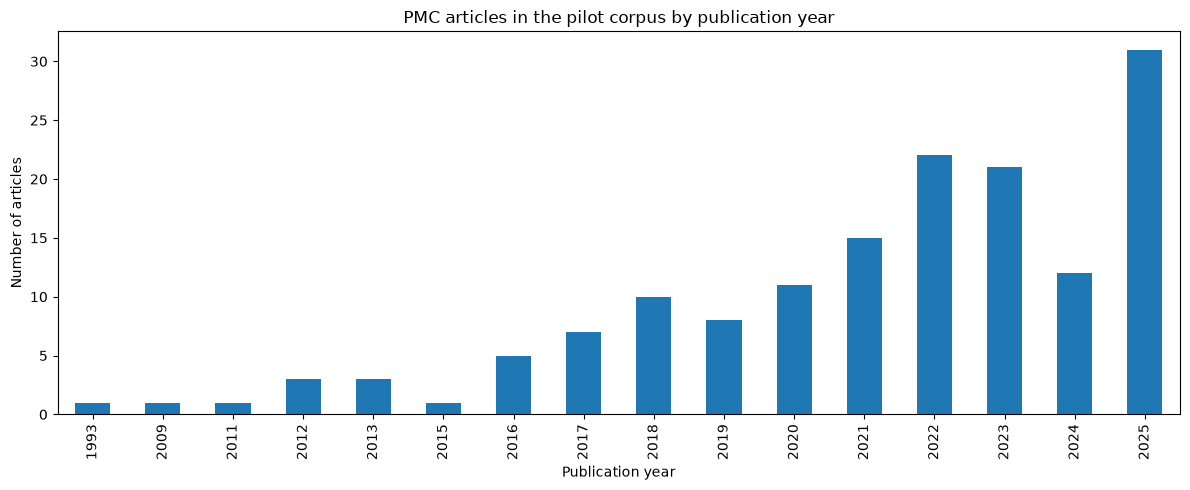

In [29]:
# Count how many unique articles were published each year
year_counts = (

    # Remove articles that don't have a publication year
    articles_df.dropna(subset=["year"])

    # Group the articles by publication year
    .groupby("year")["pmcid"]

    # Count the number of unique PMC articles for each year
    .nunique()

    # Sort the results by year, from oldest to newest
    .sort_index()
)

# Create a bar chart showing the number of articles published each year
year_counts.plot(
    kind="bar",       
    figsize=(12, 5), 
    title="PMC articles in the pilot corpus by publication year"
)

# Add labels to the graph
plt.xlabel("Publication year")
plt.ylabel("Number of articles")

# Adjust the layout so the labels fit properly
plt.tight_layout()

# Display the graph
plt.show()


In [18]:
PATTERN = {
    "Xpert MTB/RIF": r"\b(?:Xpert\s*MTB\s*/\s*RIF|GeneXpert)\b",
    "Xpert Ultra": r"\b(?:Xpert(?:\s+MTB\s*/\s*RIF)?\s+Ultra|MTB\s*/\s*RIF\s+Ultra)\b",
    "TB PCR / NAAT": r"\b(?:polymerase chain reaction|\bPCR\b|\bNAAT\b|nucleic.acid amplification)\b",
    "Mycobacterial culture": r"\b(?:mycobacterial culture|\bMGIT\b|L[oö]wenstein.Jensen|TB culture)\b",
    "AFB / smear": r"\b(?:acid.fast bacill\w*|\bAFB\b|Ziehl.Neelsen|smear microscopy)\b",
    "Biopsy / histology": r"\b(?:biops\w*|histopatholog\w*|granulomatous|caseating granuloma\w*)\b",
    "Adenosine deaminase": r"\b(?:adenosine deaminase|\bADA\b)\b",
    "Cerebrospinal fluid": r"\b(?:cerebrospinal fluid|\bCSF\b)\b",
    "Pleural fluid": r"\b(?:pleural fluid|pleural effusion)\b",
    "Fine-needle aspiration": r"\b(?:fine.needle aspiration|\bFNAC\b|\bFNA\b)\b",
    "Diagnostic accuracy terms": r"\b(?:sensitivit\w*|specificit\w*|diagnostic accurac\w*)\b",
}


In [30]:
PATTERN = {
    "Biopsy / histology": r"\b(?:biops\w*|histolog\w*)\b",
    "Endoscopy": r"\bendoscop\w*\b",
    "Autoantibodies": (
        r"\b(?:intrinsic.factor.antibod\w*|"
        r"parietal.cell.antibod\w*|"
        r"anti.parietal.cell)\b"
    ),
    "Vitamin B12": r"\b(?:vitamin B12|cobalamin)\b",
    "Gastrin": r"\bgastrin\b",
    "Pepsinogen": r"\bpepsinogen\w*\b"
}

In [31]:
# Select the main sections of the articles
# JATS stores section names as full headings and may include subsections
main_sections = [
    "abstract", "introduction", "background",
    "methods", "materials", "patients",
    "results", "discussion", "conclusion", "case"
]

# Exclude references, tables, figures and headings
analysis_df = passages_df[
    passages_df["section"].fillna("").str.lower().apply(
        lambda section: any(
            name in section for name in main_sections
        )
    )
    &
    (passages_df["type"] == "paragraph")
].copy()

# Include abstracts, which have a separate passage type in JATS
analysis_df = pd.concat([
    analysis_df,
    passages_df[passages_df["type"] == "abstract"]
]).drop_duplicates(subset=["pmcid", "passage_id"])

# Preliminary diagnostic categories
patterns = PATTERN

for category, pattern in patterns.items():
    analysis_df[category] = analysis_df["text"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

# Combine passages into article-level indicators
paper_hits = (
    analysis_df.groupby("pmcid")[list(patterns)]
    .any()
)

trend_df = articles_df[
    ["pmcid", "year"]
].merge(
    paper_hits,
    on="pmcid",
    how="left"
)

for category in patterns:
    trend_df[category] = trend_df[category].fillna(False).astype(bool)

trend_df = trend_df.dropna(subset=["year"])

# Percentage of papers mentioning each category per year
trends = (
    trend_df.groupby("year")[list(patterns)]
    .mean()
    .mul(100)
)

display(trends.round(1))


,Biopsy / histology,Endoscopy,Autoantibodies,Vitamin B12,Gastrin,Pepsinogen
year,,,,,,
1993,0.0,0.0,0.0,0.0,0.0,0.0
2009,100.0,100.0,100.0,100.0,100.0,0.0
2011,100.0,0.0,0.0,100.0,100.0,0.0
2012,66.7,66.7,100.0,66.7,66.7,33.3
2013,100.0,66.7,33.3,66.7,33.3,0.0
2015,100.0,100.0,0.0,0.0,0.0,0.0
2016,60.0,40.0,40.0,40.0,60.0,20.0
2017,85.7,42.9,71.4,57.1,42.9,14.3
2018,70.0,60.0,70.0,60.0,40.0,10.0


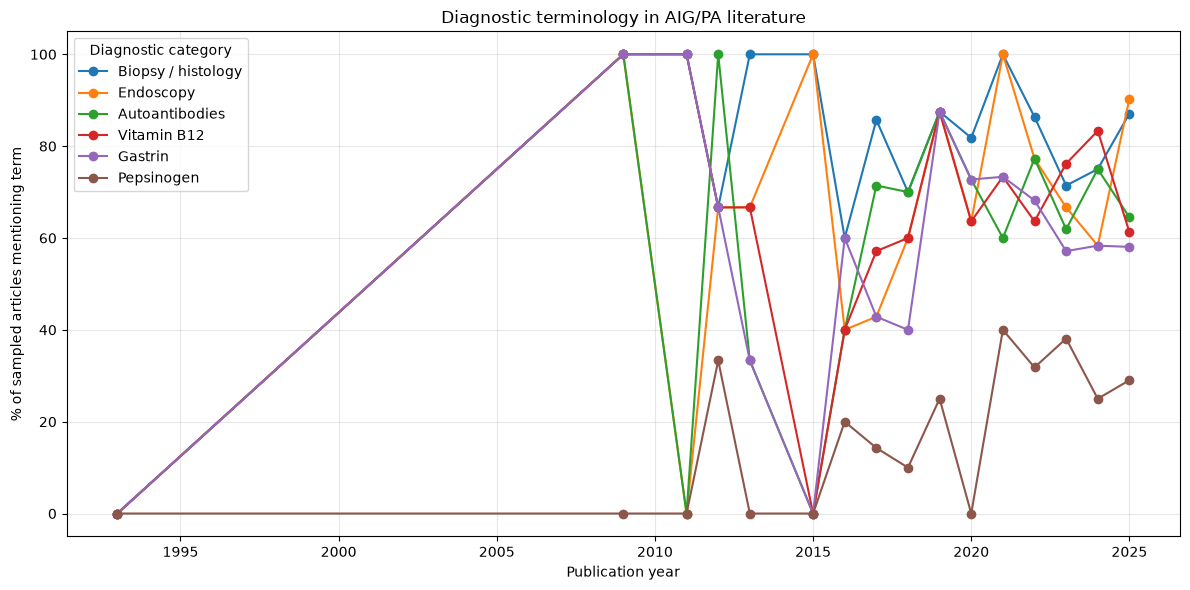

In [ ]:
trends.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title(f"Diagnostic terminology in {CONDITION} literature")
plt.xlabel("Publication year")
plt.ylabel("% of sampled articles mentioning term")
plt.legend(title="Diagnostic category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Load the processed article metadata
articles_df = pd.read_parquet(
    f"pmc/{CONDITION}/processed/articles.parquet"
)

# Load the processed text passages
passages_df = pd.read_parquet(
    f"pmc/{CONDITION}/processed/passages.parquet"
)